# Esplorare e classificare i pinguini con Gemini · soluzione
**Script intelligenti: sviluppare modelli di Machine Learning con il codice**

I dati: **Palmer Penguins**, 344 pinguini di tre specie (Adelie, Chinstrap, Gentoo) misurati alla stazione di
ricerca Palmer, in Antartide, tra il 2007 e il 2009 (Horst, Hill e Gorman, licenza CC0).

Il notebook segue la lezione: gli esercizi in Colab dei blocchi 1, 3, 4 e 5, con gli stessi prompt delle slide
(il blocco 2 si fa sulla scheda).

Oggi non scriviamo codice a mano: lo scrive **Gemini**, l'assistente di Colab. Il nostro lavoro è chiedere bene e
controllare il risultato.

| | |
|---|---|
| **1 · Chiedi chiaro** | che cosa vuoi, con quali dati, in che forma vuoi il risultato |
| **2 · Leggi** | il codice proposto, anche senza capirlo tutto: quali dati usa? che cosa calcola? |
| **3 · Esegui** | e guarda che cosa succede, errori compresi |
| **4 · Controlla** | il risultato torna con quello che sai? I numeri sono plausibili? |

> **Versione per il docente.** Ogni tappa ha il codice di una soluzione possibile, già eseguito. Gemini
> scriverà codice diverso, a volte con nomi diversi: va bene, conta che i risultati tornino.

## Come chiedere a Gemini
1. In una cella di codice vuota, cliccate su **genera** (oppure aprite il pannello di Gemini, in alto a destra).
2. Scrivete la richiesta in italiano: potete copiare il prompt di esempio.
3. Leggete il codice proposto prima di accettarlo.
4. Eseguitelo con ▶ e guardate il risultato.

*Se Gemini non è disponibile:* usate ChatGPT o Claude in un'altra scheda e incollate qui il codice.

## Preparazione
Eseguite questa cella con ▶: scarica i dati. Se il download non funziona, caricate i file a mano dal pannello **File** (l'icona a forma di cartella a sinistra).

In [1]:
# Scarica i file dei dati nella cartella di lavoro di Colab.
import os
import urllib.request

if not os.path.exists("penguins.csv"):
    urllib.request.urlretrieve("https://raw.githubusercontent.com/matteolimoncini/script-intelligenti/main/incontro-2/dati/penguins.csv", "penguins.csv")
print("File pronti:", "penguins.csv")

File pronti: penguins.csv


## Blocco 1 · Guardare i dati prima di usarli
Prima di addestrare un modello si guardano i dati: quanti sono, che cosa manca, come sono fatti i numeri, se ci
sono valori strani, che cosa va insieme, che cosa può ingannare. Si chiama **analisi esplorativa dei dati**, in
inglese *Exploratory Data Analysis* (**EDA**).

**Prompt 1a** (copiatelo in Gemini):

> Carica penguins.csv con pandas. Dimmi quante righe e colonne ha, il tipo di ogni colonna e quanti valori mancano
> in ciascuna. Poi mostrami le statistiche descrittive delle colonne numeriche.

*Parole:* **pandas** è la libreria di Python per lavorare con le tabelle. Le **statistiche descrittive** sono i numeri
che riassumono una colonna: quanti valori (count), media (mean), minimo, massimo, mediana (il valore a metà, 50%);
il 25% e il 75% dicono che un quarto dei pinguini sta sotto, un quarto sopra.

In [2]:
import pandas as pd

df = pd.read_csv("penguins.csv")
print("Righe e colonne:", df.shape)
print()
print("Tipi di dati:")
print(df.dtypes)
print()
print("Valori mancanti per colonna:")
print(df.isna().sum())

Righe e colonne: (344, 8)

Tipi di dati:
species               object
island                object
bill_length_mm       float64
bill_depth_mm        float64
flipper_length_mm    float64
body_mass_g          float64
sex                   object
year                   int64
dtype: object

Valori mancanti per colonna:
species               0
island                0
bill_length_mm        2
bill_depth_mm         2
flipper_length_mm     2
body_mass_g           2
sex                  11
year                  0
dtype: int64


In [3]:
df.describe().round(2)

,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,year
count,342.00,342.00,342.00,342.00,344.00
mean,43.92,17.15,200.92,4201.75,2008.03
std,5.46,1.97,14.06,801.95,0.82
min,32.10,13.10,172.00,2700.00,2007.00
25%,39.22,15.60,190.00,3550.00,2007.00
50%,44.45,17.30,197.00,4050.00,2008.00
75%,48.50,18.70,213.00,4750.00,2009.00
max,59.60,21.50,231.00,6300.00,2009.00


**Controllate:** 344 righe e 8 colonne? Quanti pinguini non hanno nessuna misura? Quanti non hanno il sesso?
Peso medio e mediana sono uguali?

**Prompt 1b:**

> Fai un istogramma del peso e un boxplot del peso per specie.

*Parole:* l'**istogramma** è fatto di barre che contano quanti pinguini ci sono in ogni fascia di peso; il **boxplot**
è una scatola che contiene la metà centrale dei pinguini, con una linea alla mediana. I punti fuori dai «baffi» sono
valori lontani da tutti gli altri: si chiamano **outlier**.

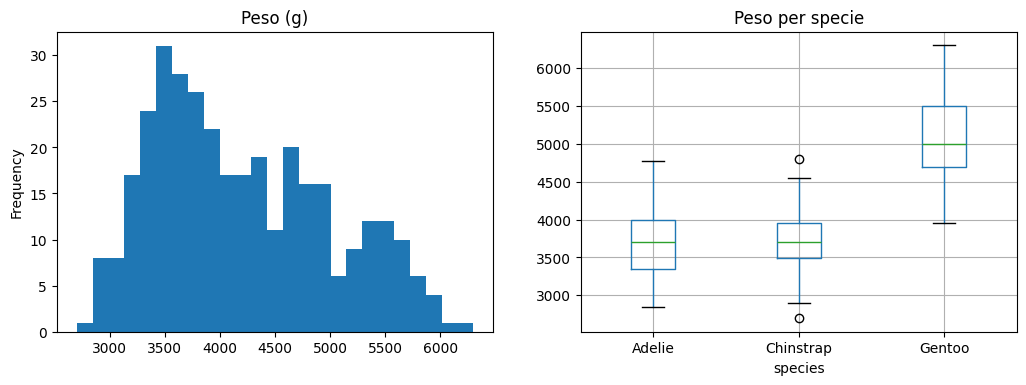

In [4]:
import matplotlib.pyplot as plt

fig, axs = plt.subplots(1, 2, figsize=(12, 4))
df["body_mass_g"].plot.hist(bins=25, ax=axs[0], title="Peso (g)")
df.boxplot(column="body_mass_g", by="species", ax=axs[1])
axs[1].set_title("Peso per specie"); fig.suptitle("")
plt.show()

**Controllate:** quante «gobbe» ha l'istogramma? Quale specie pesa di più?

**Prompt 1c:**

> Fai un grafico a dispersione di lunghezza e profondità del becco, prima senza colori e poi colorato per specie, e
> calcola la correlazione tra le due misure su tutti i pinguini e dentro ogni specie.

*Parole:* nel **grafico a dispersione** c'è un punto per ogni pinguino: in orizzontale una misura, in verticale
l'altra. La **correlazione** è un numero da −1 a 1: vicino a 1 le due misure crescono insieme, vicino a −1 una cresce e
l'altra cala, vicino a 0 non c'è legame.

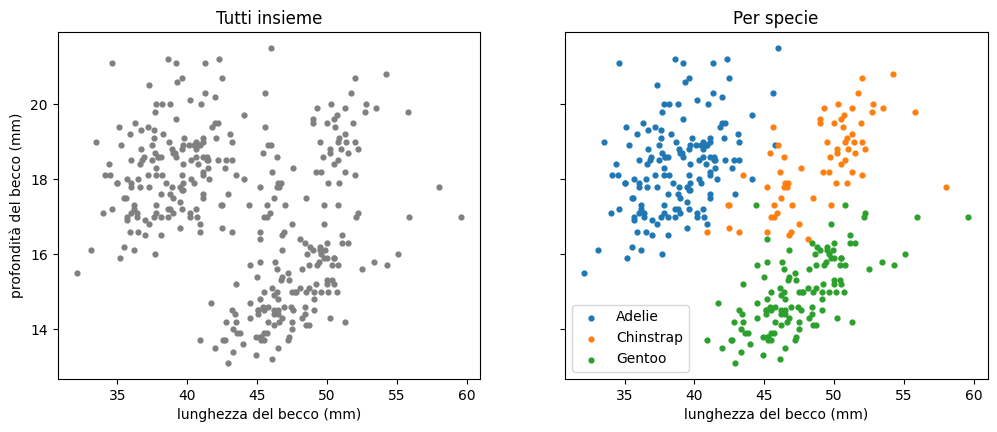

Correlazione su tutti i pinguini: -0.24
Adelie 0.39
Chinstrap 0.65
Gentoo 0.64


In [5]:
colori = {"Adelie": "tab:blue", "Chinstrap": "tab:orange", "Gentoo": "tab:green"}
fig, axs = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
axs[0].scatter(df["bill_length_mm"], df["bill_depth_mm"], color="gray", s=12)
axs[0].set_title("Tutti insieme")
for specie, gruppo in df.groupby("species"):
    axs[1].scatter(gruppo["bill_length_mm"], gruppo["bill_depth_mm"], s=12, color=colori[specie], label=specie)
axs[1].set_title("Per specie"); axs[1].legend()
for a in axs:
    a.set_xlabel("lunghezza del becco (mm)")
axs[0].set_ylabel("profondità del becco (mm)")
plt.show()

print("Correlazione su tutti i pinguini:", round(df["bill_length_mm"].corr(df["bill_depth_mm"]), 2))
for specie, gruppo in df.groupby("species"):
    print(specie, round(gruppo["bill_length_mm"].corr(gruppo["bill_depth_mm"]), 2))

**Controllate:** che cosa succede alla correlazione quando la guardate dentro ogni specie?

**Se avete tempo:**

> Fammi una tabella che incrocia isola e specie.

In [6]:
pd.crosstab(df["island"], df["species"])

species,Adelie,Chinstrap,Gentoo
island,,,
Biscoe,44,0,124
Dream,56,68,0
Torgersen,52,0,0


**Controllate:** che cosa notate nella tabella isola × specie? L'isola potrebbe ingannare un modello?

**Che cosa si deve vedere:** 344 righe e 8 colonne; 2 pinguini senza nessuna misura e 11 senza sesso. Peso medio 4201,75 g,
mediana 4050 g: la media è tirata verso destra dai Gentoo, molto più pesanti (due gobbe nell'istogramma, Gentoo in alto
nel boxplot; due Chinstrap fuori dai baffi, 2700 g e 4800 g). La correlazione tra lunghezza e profondità del becco è
−0,24 su tutti i pinguini ma positiva dentro ogni specie (0,39; 0,65; 0,64): è il paradosso di Simpson. Nella tabella
isola × specie: Gentoo solo su Biscoe, Chinstrap solo su Dream. L'isola è una scorciatoia: funziona in questi dati, ma
non con pinguini di altre isole.

## Blocco 3 · Due modi di decidere: l'albero
Il **blocco 2** (domande sì/no, indice di Gini, matrice di confusione) si fa sulla scheda, senza computer. Ora
lo stesso lavoro lo fa il computer.

**Prompt 3a:**

> Elimina le righe senza misure. Prepara X con le quattro misure numeriche e y con la specie. Dividi in
> addestramento e test (80/20, stratificato, random_state=42).

*Parole:* **X** è la tabella delle caratteristiche (le quattro misure), **y** la colonna della risposta (la specie).
**80/20, stratificato**: 80% per imparare, 20% per il test, con le specie nelle stesse proporzioni.
**random_state=42** fissa il sorteggio: tutti ottengono la stessa divisione e gli stessi numeri (42 è un numero
qualunque).

In [7]:
from sklearn.model_selection import train_test_split

misure = ["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"]
dati = df.dropna(subset=misure)
X = dati[misure]
y = dati["species"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
print("Righe rimaste:", len(dati))
print("Addestramento:", len(X_train), " Test:", len(X_test))
print()
print(y_train.value_counts(normalize=True).round(2))
print(y_test.value_counts(normalize=True).round(2))

Righe rimaste: 342
Addestramento: 273  Test: 69

species
Adelie       0.44
Gentoo       0.36
Chinstrap    0.20
Name: proportion, dtype: float64
species
Adelie       0.43
Gentoo       0.36
Chinstrap    0.20
Name: proportion, dtype: float64


**Controllate:** 342 pinguini, 273 per imparare e 69 per il test?

**Prompt 3b:**

> Addestra un albero di decisione di profondità 3 sui dati di addestramento. Calcola l'accuratezza sul test, mostra la
> matrice di confusione e disegna l'albero.

*Parole:* **profondità 3** vuol dire al massimo tre domande, una dopo l'altra. L'**accuratezza** è la percentuale di
risposte giuste. La **matrice di confusione** è la tabella che incrocia la specie vera con quella indovinata dal
modello.

Accuratezza sul test: 0.986


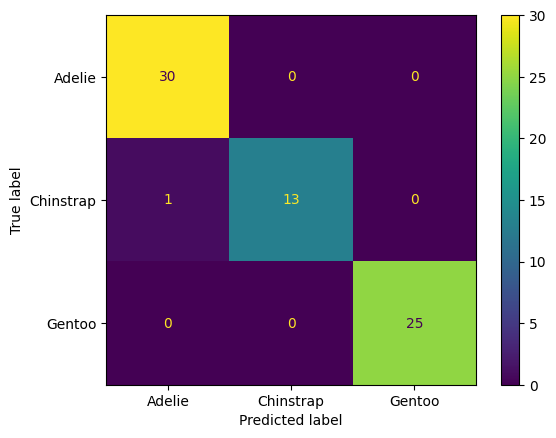

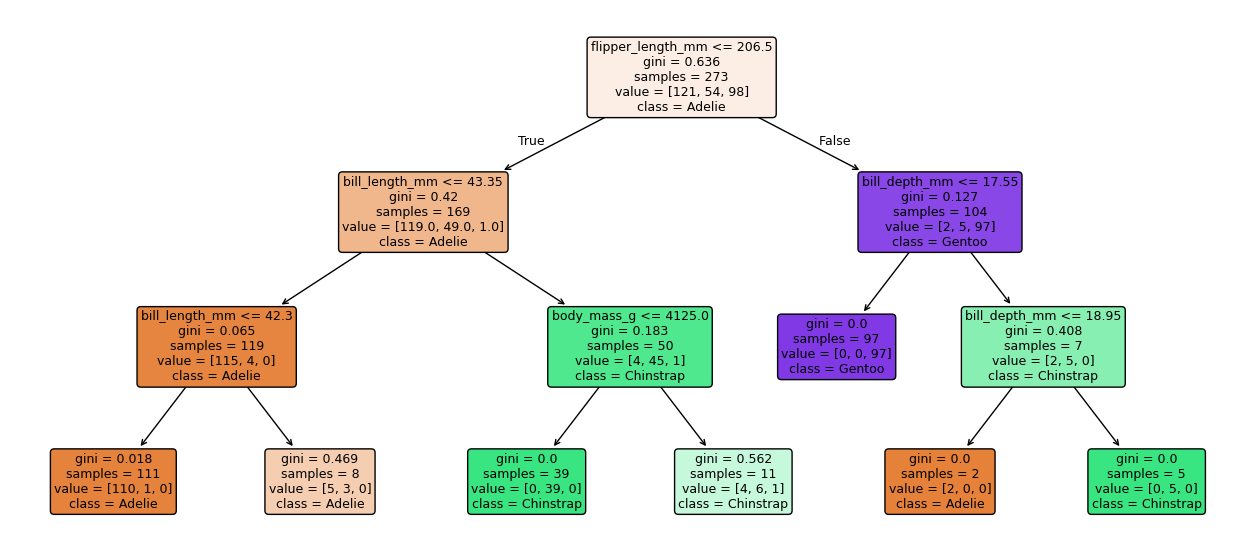

In [8]:
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, ConfusionMatrixDisplay

albero = DecisionTreeClassifier(max_depth=3, random_state=0)
albero.fit(X_train, y_train)
previsioni = albero.predict(X_test)
print("Accuratezza sul test:", round(accuracy_score(y_test, previsioni), 3))
ConfusionMatrixDisplay.from_predictions(y_test, previsioni)
plt.show()

plt.figure(figsize=(16, 7))
plot_tree(albero, feature_names=misure, class_names=albero.classes_, filled=True, rounded=True, fontsize=9)
plt.show()

**Controllate**
- Quanti pinguini su 69 sono classificati bene?
- La prima domanda dell'albero è la stessa che avete trovato nella sfida sulla scheda?
- Dove sbaglia? Quali specie si confondono?

**Che cosa si deve vedere:** 342 pinguini, 273 di addestramento e 69 di test; con la divisione stratificata le proporzioni delle
specie sono quasi identiche nei due gruppi. L'albero classifica bene 68 pinguini su 69 (98,6%); l'unico errore è un
Chinstrap scambiato per Adelie, come il pinguino D della sfida. La prima domanda riguarda la pinna (circa 206 mm). Con
un'altra divisione (un altro random_state) i numeri cambiano un po': in media circa 95%.

## Blocco 3 · Due modi di decidere: i vicini
Un altro modo di decidere: per un pinguino nuovo si cercano i pinguini più simili (i più vicini sul grafico) e vince
la specie più frequente tra loro. Si chiama **k vicini più vicini**, in inglese *k-nearest neighbors* (**KNN**): k è
quanti vicini si guardano.

**Prompt 3c:**

> Addestra un KNN con k = 5 sugli stessi dati di addestramento e calcola l'accuratezza sul test.

In [9]:
from sklearn.neighbors import KNeighborsClassifier

knn = KNeighborsClassifier(n_neighbors=5).fit(X_train, y_train)
print("KNN senza scaling:", round(knn.score(X_test, y_test), 3))

KNN senza scaling: 0.739


**Controllate:** è meglio o peggio dell'albero? Guardate le colonne: in che unità sono le misure?

Il peso è in migliaia di grammi, il becco in decine di millimetri: nella distanza conta quasi solo il peso. Per
rimediare si **standardizzano** le misure (in inglese *scaling*): per ognuna si guarda quanto un pinguino sta sopra o
sotto la media, contato in deviazioni standard (la distanza tipica dalla media). Media e deviazione standard si
calcolano **solo sui dati di addestramento**: se si usa anche il test, il modello «sbircia» la verifica, ed è un errore
che si chiama **leakage**.

**Prompt 3d:**

> Ripeti il KNN standardizzando le misure con StandardScaler, calcolato solo sui dati di addestramento.

*Parole:* **StandardScaler** è lo strumento di scikit-learn (la libreria di Python per il Machine Learning) che
standardizza le misure.

In [10]:
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

# la pipeline calcola media e deviazione standard solo sui dati di addestramento
knn_scalato = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5)).fit(X_train, y_train)
print("KNN con scaling:  ", round(knn_scalato.score(X_test, y_test), 3))

KNN con scaling:   1.0


**Domanda:** che cosa succederebbe calcolando media e deviazione standard su tutti i pinguini, prima di dividere?

**Che cosa si deve vedere:** con questa divisione il KNN arriva al 74% senza standardizzare e al 100% (69 su 69) con le misure
standardizzate: senza, la distanza guarda quasi solo il peso. Calcolare lo scaler su tutti i dati sarebbe leakage: il
modello userebbe informazioni del test, e il risultato sarebbe troppo bello.

## Blocco 4 · Contare gli errori
Ora il modello indovina il **sesso**. Scegliamo il gruppo che ci interessa trovare, le femmine, e lo chiamiamo
**positivo**. Un **vero positivo** (TP) è una femmina riconosciuta; un **falso negativo** (FN) è una femmina scambiata
per maschio; un **falso positivo** (FP) è un maschio scambiato per femmina; un **vero negativo** (TN) è un maschio
riconosciuto.

**Prompt 4:**

> Ora predici il sesso invece della specie. Elimina le righe senza sesso, dividi in addestramento e test (80/20,
> stratificato), addestra un albero di profondità 3 e mostrami la matrice di confusione, con female come classe
> positiva.

*Parole:* nel file il sesso è scritto **female** (femmina) e **male** (maschio).

In [11]:
from sklearn.metrics import confusion_matrix

dati_sesso = df.dropna(subset=misure + ["sex"])
Xs = dati_sesso[misure]
ys = dati_sesso["sex"]
Xs_train, Xs_test, ys_train, ys_test = train_test_split(Xs, ys, test_size=0.2, stratify=ys, random_state=42)
print("Pinguini con il sesso:", len(dati_sesso), " nel test:", len(Xs_test))

m3 = DecisionTreeClassifier(max_depth=3, random_state=0).fit(Xs_train, ys_train)
cm = confusion_matrix(ys_test, m3.predict(Xs_test), labels=["female", "male"])
print(cm)
print("TP", cm[0, 0], " FN", cm[0, 1], " FP", cm[1, 0], " TN", cm[1, 1])

Pinguini con il sesso: 333  nel test: 67
[[25  8]
 [ 2 32]]
TP 25  FN 8  FP 2  TN 32


**Controllate:** 333 pinguini, 67 nel test; i quattro numeri della matrice sommati fanno 67. Ognuno può avere numeri
un po' diversi: dipende dal sorteggio della divisione.

**Su un foglio**, a mano, dalla vostra matrice:
- **accuratezza** = (TP + TN) / (TP + TN + FP + FN): quante risposte giuste su tutte;
- **precision** = TP / (TP + FP): quando dice «femmina», quante volte ha ragione;
- **recall** = TP / (TP + FN): delle femmine vere, quante ne trova;
- **F1** = 2 · precision · recall / (precision + recall): un voto unico, basso se uno dei due è basso.

**Poi controllate i vostri conti:** scrivete i vostri quattro numeri al posto degli zeri ed eseguite la cella con ▶.

In [12]:
TP = 25   # femmine riconosciute
FN = 8    # femmine scambiate per maschi
FP = 2    # maschi scambiati per femmine
TN = 32   # maschi riconosciuti

accuratezza = (TP + TN) / (TP + TN + FP + FN)
precision = TP / (TP + FP)
recall = TP / (TP + FN)
f1 = 2 * precision * recall / (precision + recall)
print(f"accuratezza {accuratezza:.2f}   precision {precision:.2f}   recall {recall:.2f}   F1 {f1:.2f}")

accuratezza 0.85   precision 0.93   recall 0.76   F1 0.83


**Domande**
- I vostri conti tornano? Se no, quale formula avete sbagliato?
- Quale dei quattro numeri è il più basso? Quale errore fa più spesso il modello?
- Se perdere una femmina costasse caro, quale numero guardereste?

**Che cosa si deve vedere:** 333 pinguini con il sesso, 67 nel test. Con random_state=42 (Gemini spesso lo mette da solo) la
matrice con profondità 3 è TP 25, FN 8, FP 2, TN 32 → accuratezza 0,85, precision 0,93, recall 0,76, F1 0,83. Con
un'altra divisione i numeri cambiano un po'. Il modello perde una femmina su quattro (le scambia per maschi): la recall
è il numero più basso.

## Blocco 5 · Troppo semplice o troppo a memoria
Un modello troppo semplice sbaglia anche sui pinguini da cui ha imparato: si chiama **underfitting**. Un modello che
impara a memoria è perfetto sui pinguini da cui ha imparato, ma peggiore su quelli nuovi: si chiama **overfitting**.
Con l'albero, più è profondo, più rischia di imparare a memoria.

**Prompt 5:**

> Sempre sul sesso, addestra alberi di profondità da 1 a 10. Per ogni profondità ripeti con 30 divisioni diverse
> (random_state da 0 a 29) e fai la media dell'accuratezza su addestramento e test. Fai un grafico con le due curve.

*Perché 30 divisioni:* con una sola divisione i numeri cambiano molto a seconda del sorteggio; la media è più
affidabile.

1 0.723 0.695


2 0.869 0.859


3 0.913 0.894


4 0.933 0.883


5 0.963 0.88
6 0.978 0.884


7 0.988 0.879


8 0.994 0.875
9 0.998 0.871


10 0.999 0.873


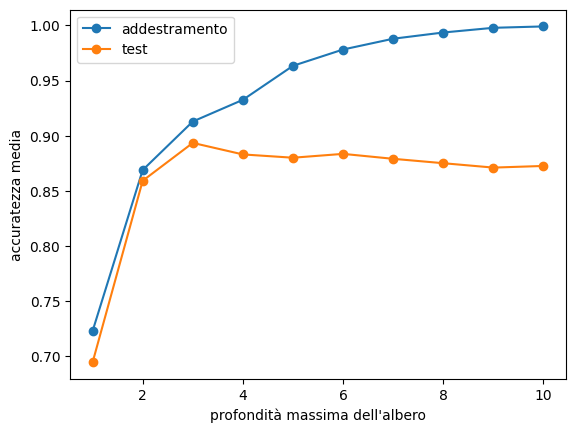

In [13]:
import numpy as np

profondita = range(1, 11)
media_train, media_test = [], []
for p in profondita:
    acc_train, acc_test = [], []
    for seme in range(30):
        a, b, c, d = train_test_split(Xs, ys, test_size=0.2, stratify=ys, random_state=seme)
        m = DecisionTreeClassifier(max_depth=p, random_state=0).fit(a, c)
        acc_train.append(m.score(a, c))
        acc_test.append(m.score(b, d))
    media_train.append(np.mean(acc_train))
    media_test.append(np.mean(acc_test))
    print(p, round(media_train[-1], 3), round(media_test[-1], 3))

plt.plot(profondita, media_train, "o-", label="addestramento")
plt.plot(profondita, media_test, "o-", label="test")
plt.xlabel("profondità massima dell'albero"); plt.ylabel("accuratezza media"); plt.legend()
plt.show()

**Controllate**
- Con profondità 1 il modello va male anche sui dati di addestramento? (underfitting)
- Dove il test è più alto?
- Con l'albero molto profondo, che cosa succede sull'addestramento e sul test? (overfitting)

**Che cosa si deve vedere:** profondità 1: circa 72% sull'addestramento e 70% sul test (underfitting); profondità 3: 91% e 89%,
il test più alto; profondità 10: quasi 100% sull'addestramento e 87% sul test (overfitting). La distanza tra le due
curve cresce: l'addestramento continua a salire, il test no. Con una sola divisione (random_state = 42) la curva del
test è irregolare e l'albero più profondo sembra persino migliore: per questo si fa la media.

## Sfide in più, per chi finisce prima
> **Quanti vicini?** Prova un KNN con le misure standardizzate per indovinare il sesso, con k da 1 a 50. Fai un
> grafico dell'accuratezza sul test: dove sta il punto giusto?

> **L'isola:** aggiungi l'isola alle quattro misure (trasformata in colonne di 0 e 1) per indovinare la specie. Che
> cosa succede? Ti fideresti di questo modello con pinguini di un'altra isola?

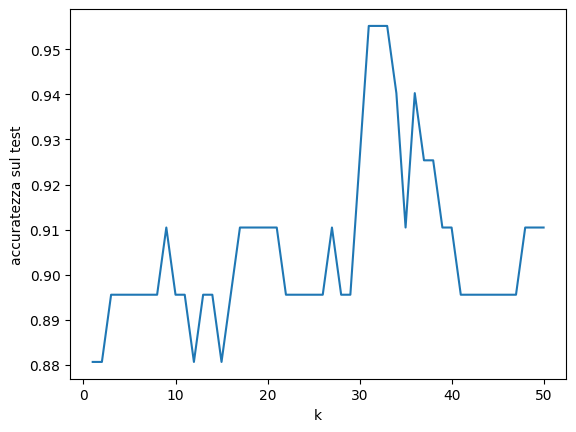

In [14]:
ks = range(1, 51)
acc = [make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k)).fit(Xs_train, ys_train).score(Xs_test, ys_test) for k in ks]
plt.plot(ks, acc); plt.xlabel("k"); plt.ylabel("accuratezza sul test"); plt.show()

In [15]:
X_isola = pd.get_dummies(dati[misure + ["island"]], columns=["island"], dtype=int)
a, b, c, d = train_test_split(X_isola, y, test_size=0.2, stratify=y, random_state=42)
print("Specie con l'isola, albero profondità 3:", round(DecisionTreeClassifier(max_depth=3, random_state=0).fit(a, c).score(b, d), 3))

Specie con l'isola, albero profondità 3: 0.986


**Che cosa si deve vedere:** con k = 1 il KNN segue anche i singoli pinguini strani (100% sull'addestramento, circa 87% sul
test); con k intorno a 15 addestramento e test si avvicinano (circa 92%). Con l'isola l'albero resta al 98,6%: qui
l'isola non aggiunge niente, ma è una scorciatoia che fallirebbe con pinguini di altre isole.

## Per finire
Avete guardato un dataset vero prima di usarlo, costruito e confrontato due modi di decidere (l'albero e i vicini),
contato gli errori e visto la differenza tra un modello troppo semplice e uno che impara a memoria. **Nell'incontro 3**
predirete un numero (il peso) e cercherete gruppi senza sapere la specie, sugli stessi pinguini.